# 演習1：2×2行列だけでQPE・BPE・BPDEを理解する

$$K=\operatorname{diag}(1/4,3/4),\qquad U=e^{2\pi iK}.$$

固有状態は$|0\rangle,|1\rangle$、固有位相は$\phi_0=1/4,\phi_1=3/4$です。
この既知の答えを回路で読み直し、**数式→回路→測定→推定**の対応を確認します。
本冊だけを上から実行すれば、以下の4つを比較できます。

| 方法 | 入力・回路 | 測定から得る量 |
|---|---|---|
| IQFT型QPE | 系1＋補助$m$、制御$U^{2^r}$と逆QFT | 位相を表すビット列 |
| BPE | 系1＋補助1、制御$U^L$の干渉測定を繰り返す | 一つの固有位相の事後分布 |
| BPDE・Fig. 1B型 | 補助の枝ごとに二状態を準備し、系に$U^L$ | 差$\Delta=\phi_1-\phi_0$の事後分布 |
| BPDE・Fig. 1C型 | 準備→$U^L$→逆準備、全ビット測定 | 全0の頻度から差の事後分布 |

確率は理想計算、countsは模擬測定です。IBMアカウントは使いません。
「位相」は1周を1とする数、「補正位相$\beta$」はラジアンです。
まず予想してからコードを実行し、最後に各節の課題へ進んでください。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"

### 実行準備

次のセルはライブラリと描画関数を定義します。`draw`は回路図、`show_probs`は
厳密確率と指定shotsの模擬測定を描きます。推定する物理量はまだ設定しません。

In [2]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
TAU = 2 * np.pi
ATOL = 1e-10

def draw(qc, fold=110):
    # 回路を画像で表示。数値計算にはこの描画関数は使わない。
    fig = qc.draw(output="mpl", fold=fold)
    display(fig)
    plt.close(fig)

def draw_measured(qc, qubits):
    # 描画用のコピーだけに測定を追加。厳密確率は測定前の回路から計算する。
    measured = qc.copy()
    readout = ClassicalRegister(len(qubits), "readout")
    measured.add_register(readout)
    measured.measure(qubits, readout)
    draw(measured)

def show_probs(probabilities, title, ax=None, shots=None, seed=123):
    p = np.asarray(probabilities, dtype=float)
    m = int(np.log2(len(p)))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3))
    x = np.arange(len(p))
    ax.bar(x, p, width=0.65, label="Exact probability", alpha=0.75)
    if shots:
        counts = np.random.default_rng(seed).multinomial(shots, p / p.sum())
        ax.plot(x, counts / shots, "ko", ms=4, label=f"{shots} simulated shots")
    ax.set_xticks(x, [format(i, f"0{m}b") for i in x], rotation=60 if m > 3 else 0)
    ax.set(xlabel="Measured bits (MSB ... LSB)", ylabel="Probability", title=title)
    ax.legend(fontsize=8)
    return ax

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__, "Qiskit:", qiskit.__version__)
print("以降のshot/countはすべてシミュレーションです。")

Python: 3.12.7
NumPy: 2.4.6 Matplotlib: 3.10.0 Qiskit: 2.4.1
以降のshot/countはすべてシミュレーションです。


## 0．行列・固有位相・ビット順を固定する

$$U|j\rangle=e^{2\pi i\phi_j}|j\rangle,\quad
U^L|j\rangle=e^{2\pi iL\phi_j}|j\rangle,\quad \Delta=1/2.$$

| 入力 | 位相 | 二進数3桁 | QPEの出力整数$y=8\phi$ |
|---|---:|---|---:|
| $|0\rangle$ | $1/4$ | $0.010_2$ | 2 |
| $|1\rangle$ | $3/4$ | $0.110_2$ | 6 |

$m$はQPEの補助数、$r$はべき$2^r$の指数、$L$はUの反復回数です。
例えば$U^5$は$L=5$回の操作であり、第5桁の測定ではありません。
$L\phi_0=5/4$周は、周期1で見れば$1/4$周です。

Qiskitのケットは$|q_{n-1}\cdots q_0\rangle$順です。
QPEの補助は$q_0\ldots q_{m-1}$、系は$q_m$。
以降の2 qubit回路は$q_0=a$（補助）、$q_1=s$（系）で、配列のケットは$|s,a\rangle$です。
説明中の$|a,s\rangle$とは表示順が逆です。

次セルで`K`、`PHASES`、`GAP`と入力状態を定義します。
`psi_mixed`は二つの固有状態の**純粋な重ね合わせ**で、密度行列の混合状態ではありません。

In [3]:
PHASES = np.array([1/4, 3/4])
K = np.diag(PHASES)
GAP = PHASES[1]-PHASES[0]
zero = np.array([1,0], complex)
one = np.array([0,1], complex)
psi_mixed = np.sqrt(.75)*zero + np.sqrt(.25)*one

def u_power(L, phases=PHASES):
    return np.diag(np.exp(1j*TAU*L*np.asarray(phases)))

print('K =',K,'\nU =',u_power(1))
for phase in PHASES:
    print(f'phase={phase}: 0.{int(8*phase):03b}_2')
assert GAP == .5
np.testing.assert_allclose(u_power(1).conj().T@u_power(1),np.eye(2),atol=ATOL)

K = [[0.25 0.  ]
 [0.   0.75]] 
U = [[ 0.+1.j  0.+0.j]
 [ 0.+0.j -0.-1.j]]
phase=0.25: 0.010_2
phase=0.75: 0.110_2


## 1．共通部品：位相を0/1の確率へ変える

位相因子だけでは状態の測定確率は変わりません。補助の二つの枝を干渉させます。
下の●は制御、P(β)=diag(1,exp(iβ))、MはZ基底の測定です。時間は左から右です。

```text
a: |0> ──H────●────P(β)──H──M
              │
s: |ψ> ─────[U^L]────────────
```

系が固有状態$|\phi\rangle$なら、制御Uの後は
$$(|0\rangle+e^{2\pi iL\phi}|1\rangle)|\phi\rangle/\sqrt2.$$
最後のHで二つの振幅が足し引きされ、
$$P(a=0\mid\phi,L,\beta)=\frac{1+\cos(2\pi L\phi+\beta)}2.$$
候補$\epsilon$に対し$\beta=-2\pi L\epsilon$とすると、ピークは
$\epsilon=\phi+k/L$です。長時間は感度を上げると同時に候補も増やします。

**予想：** $\phi=1/4$、$L=1,2,4$では、区間$[0,1)$に何個のピークがあるか。

<details><summary>解答例</summary>
順に1、2、4個です。ピーク条件はε=1/4+k/Lで、周期1の区間にL個あります。
</details>

次セルは回路の状態ベクトルと上の余弦式を照合し、候補を掃引します。

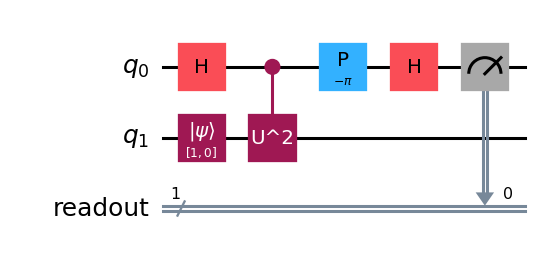

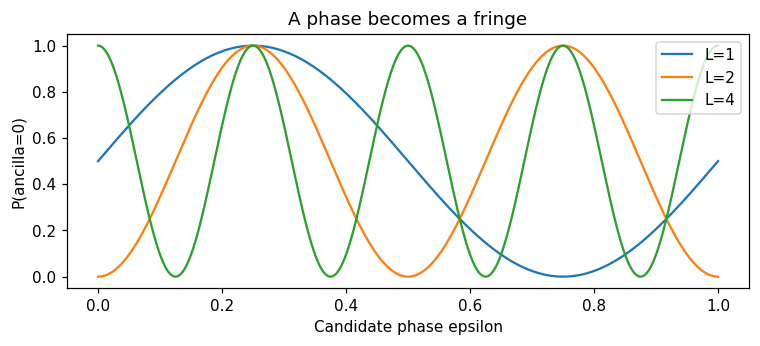

In [4]:
def ramsey_circuit(psi, L=1, beta=0.0):
    qc = QuantumCircuit(2)
    qc.initialize(psi, 1)
    qc.h(0)
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}").control(), [0, 1])
    qc.p(beta, 0)
    qc.h(0)
    return qc

def ancilla_zero(qc):
    return float(Statevector.from_instruction(qc).probabilities([0])[0])

def bpe_probability(weights, L, beta):
    # betaはスカラーでも配列でもよい。
    amplitude = np.dot(weights, np.exp(1j * TAU * L * PHASES))
    return 0.5 * (1 + np.real(np.exp(1j * beta) * amplitude))

draw_measured(ramsey_circuit(zero, L=2, beta=-TAU * 2 * PHASES[0]), [0])
eps = np.linspace(0, 1, 801)
fig, ax = plt.subplots(figsize=(8, 3))
for L in [1, 2, 4]:
    ax.plot(eps, bpe_probability([1, 0], L, -TAU*L*eps), label=f"L={L}")
    for e in [0.03, 0.125, 0.36]:
        actual = ancilla_zero(ramsey_circuit(zero, L, -TAU*L*e))
        assert np.isclose(actual, bpe_probability([1, 0], L, -TAU*L*e), atol=ATOL)
ax.set(xlabel="Candidate phase epsilon", ylabel="P(ancilla=0)", title="A phase becomes a fringe")
ax.legend(); plt.show()

### 課題1：干渉と周期

1. 最後のHを外して補助を測ると、位相は読めるか。
2. $L=8$を図に追加し、候補が$1/L$ずつ繰り返すことを確認する。

<details><summary>解答例</summary>
最後のHの前は補助0/1の絶対値が等しく、Z測定はどちらも1/2です。
候補を1/L動かすと余弦の引数が2π変わるため、ピークがL個あります（端点1は0と同一）。
</details>

## 2．IQFT型QPE：位相をビット列へ写す

一度のQPE回路で補助$m$個を使い、$L=1,2,4,\ldots,2^{m-1}$の情報を量子的にまとめます。
$m=3$の模式図です。右の3線をまとめた箱が逆QFTです。

```text
q0: |0> ──H──●──────────────┌────────┐──M
             │              │        │
q1: |0> ──H──┼───●──────────│ IQFT   │──M
             │   │          │        │
q2: |0> ──H──┼───┼───●──────└────────┘──M
             │   │   │
s : |φ> ────[U]─[U²]─[U⁴]────────────────
```

固有状態なら、逆QFT前の補助は
$$2^{-m/2}\sum_{x=0}^{2^m-1}e^{2\pi ix\phi}|x\rangle.$$
逆QFTは$|x\rangle\mapsto 2^{-m/2}\sum_y e^{-2\pi ixy/2^m}|y\rangle$なので、
$$P(y\mid\phi)=\left|2^{-m}\sum_x e^{2\pi ix(\phi-y/2^m)}\right|^2.$$
$\phi=y_0/2^m$なら同位相で足し合うのは$y=y_0$だけです。
本例では010と110が確率1で出ます。制御Uのどの補助も、逆QFT前に単独で「第r桁」を読んでいるわけではありません。

次セルの`inverse_qft`はH・制御位相・SWAPを実装し、定義行列と照合します。
`QPE_BITS`を変更して、固有状態の出力を比較してください。

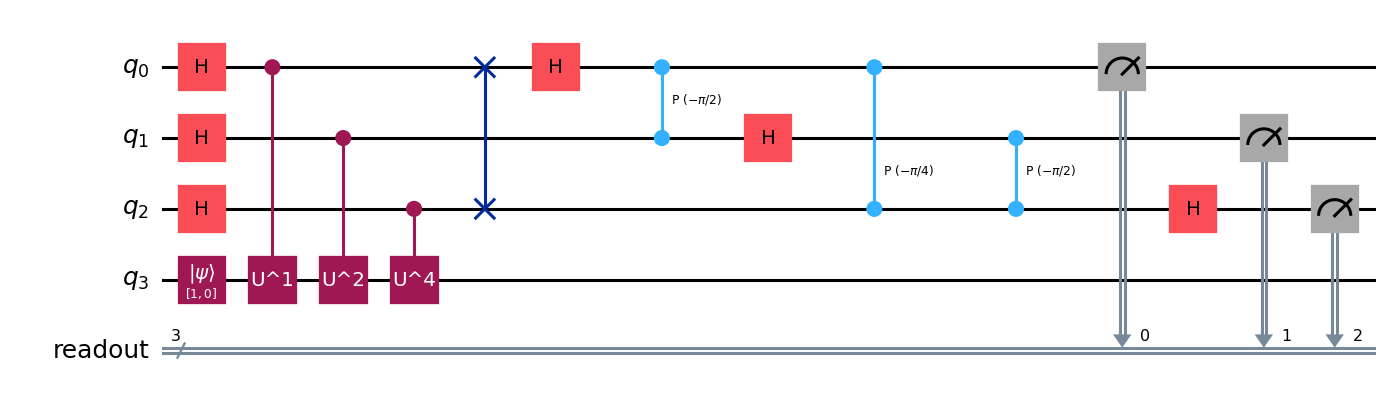

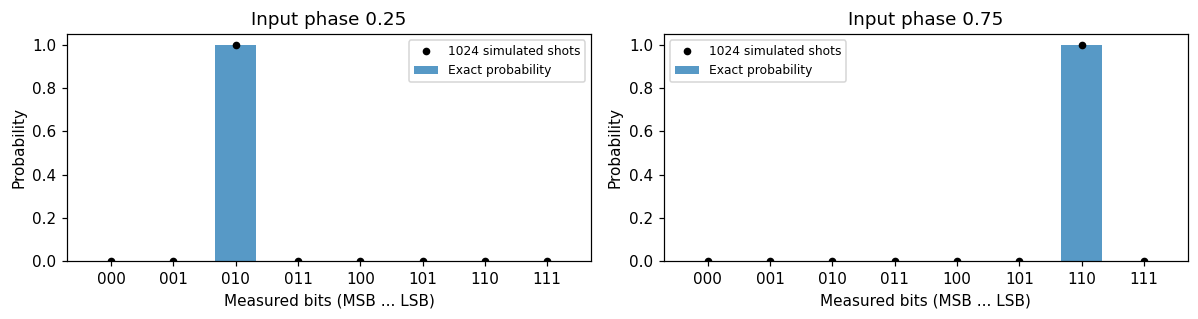

In [5]:
def inverse_qft(m):
    qc = QuantumCircuit(m, name="QFT_dg")
    for j in range(m // 2):
        qc.swap(j, m - 1 - j)
    for j in range(m):
        for ell in range(j):
            qc.cp(-np.pi / 2**(j - ell), j, ell)
        qc.h(j)
    return qc

def qpe_circuit(psi, m=3, phases=PHASES):
    qc = QuantumCircuit(m + 1)
    qc.initialize(psi, m)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(u_power(2**r, phases), label=f"U^{2**r}").control(), [r, m])
    qc.compose(inverse_qft(m), list(range(m)), inplace=True)
    return qc

def qpe_distribution(psi, m=3, phases=PHASES):
    state = Statevector.from_instruction(qpe_circuit(psi, m, phases))
    return state.probabilities(list(range(m)))

QPE_BITS = 3  # 2, 3, 4を比較
M = 2**QPE_BITS
x = np.arange(M)
np.testing.assert_allclose(Operator(inverse_qft(QPE_BITS)).data,
    np.exp(-1j*TAU*np.outer(x,x)/M)/np.sqrt(M),atol=ATOL)
draw_measured(qpe_circuit(zero,QPE_BITS),list(range(QPE_BITS)))
fig,axes=plt.subplots(1,2,figsize=(11,3))
for ax,psi,phase in zip(axes,[zero,one],PHASES):
    p=qpe_distribution(psi,QPE_BITS)
    show_probs(p,f'Input phase {phase}',ax,shots=1024)
    assert np.isclose(p[int(M*phase)],1,atol=ATOL)
plt.tight_layout();plt.show();plt.close(fig)


### 2.1．固有状態の重ね合わせを入力する

$$|\psi\rangle=\sqrt{3/4}|0\rangle+\sqrt{1/4}|1\rangle.$$
$m=3$なら、逆QFT後の状態は（ここだけ補助レジスタを先に書いて）
$$\sqrt{3/4}|010\rangle_a|0\rangle_s+\sqrt{1/4}|110\rangle_a|1\rangle_s.$$
位相の平均ではなく、固有成分ごとの位相が重なりの確率で出ます。
次セルはヒストグラムと、補助の結果に条件付けた系の状態を表示します。

ancilla=010, probability=0.750, system P(0),P(1)=[1. 0.]
ancilla=110, probability=0.250, system P(0),P(1)=[0. 1.]


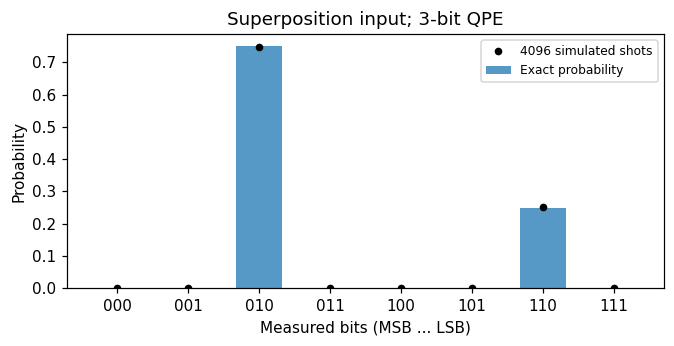

In [6]:
GROUND_WEIGHT = .75  # .25へ変更して再実行
psi_mixed=np.sqrt(GROUND_WEIGHT)*zero+np.sqrt(1-GROUND_WEIGHT)*one
p_qpe=qpe_distribution(psi_mixed,m=3)
show_probs(p_qpe,'Superposition input; 3-bit QPE',shots=4096);plt.show();plt.close('all')
expected=np.zeros(8);expected[2]=GROUND_WEIGHT;expected[6]=1-GROUND_WEIGHT
np.testing.assert_allclose(p_qpe,expected,atol=ATOL)
joint=Statevector.from_instruction(qpe_circuit(psi_mixed,m=3)).data.reshape(2,8)
for y in [2,6]:
    if p_qpe[y]>ATOL:
        conditional=joint[:,y]/np.sqrt(p_qpe[y])
        print(f'ancilla={y:03b}, probability={p_qpe[y]:.3f}, system P(0),P(1)={abs(conditional)**2}')

### 課題2：QPEの出力を読む

1. `QPE_BITS`を2、3、4へ変える。出力整数と位相y/2^mを区別して記録する。
2. `GROUND_WEIGHT`を.75から.25へ変える。変わるのはピークの場所か、頻度か。

<details><summary>解答例</summary>
位相1/4、3/4は2ビットで表せます。3ビットでは010/110、2ビットでは01/11です。
重みを変えても位相は変わらず、010と110の確率が1/4と3/4になります。
</details>

## 3．BPE：同じ干渉測定から事後分布を作る

回路は第1節と同じです。**各ショットで系と補助を準備し直し**、1個の補助を測ります。
系を測定履歴に応じて保持するiterative QPEとは異なります。

```text
(毎ショット) 準備 |φ> → H_a → controlled-U^L → P_a(β) → H_a → M_a
                                     ↓ 0/1をR回集計
事前 p(φ) → 二項尤度を掛ける → 正規化 → 事後 p(φ|D) → 次の事前
```

1設定$(L,\beta)$でR shots中$n_0$回の0を得たら、
$$p_{\rm new}(\phi)=\frac{p_{\rm old}(\phi)
 P_0(\phi)^{n_0}[1-P_0(\phi)]^{R-n_0}}{\text{正規化定数}}.$$
二項係数は候補φに依存しないため正規化で消えます。
初期分布は$[0,1)$の一様分布です。二つの補正位相0と−π/2を使い、余弦の対称な候補を区別します。

次セルは更新関数だけを定義します。内部では小さな確率の積を安定に計算するため対数を使います。
`data`の各行は(L,β,R,n₀,生成に使った厳密確率)、`posteriors[k]`はk+1設定後の分布です。

In [7]:
GRID = (np.arange(4096) + 0.5) / 4096  # 周期の端点を重複させない

def single_phase_model(phi, L, beta):
    return 0.5 * (1 + np.cos(TAU*L*phi + beta))

def bayes_update(grid, settings, true_probability, shots=256, seed=20261108):
    rng = np.random.default_rng(seed)
    logpost = np.zeros_like(grid)
    posteriors, data = [], []
    for L, beta in settings:
        true_p = float(np.clip(true_probability(L, beta), 0, 1))
        # 同じ理想確率の微小な丸め差で、乱数分岐が変わらないよう生成確率を揃える。
        true_p = round(true_p, 12)
        n0 = int(rng.binomial(shots, true_p))
        model_p = np.clip(single_phase_model(grid, L, beta), 1e-12, 1-1e-12)
        logpost += n0*np.log(model_p) + (shots-n0)*np.log1p(-model_p)
        logpost -= np.max(logpost)
        post = np.exp(logpost); post /= post.sum()
        posteriors.append(post)
        data.append((L, beta, shots, n0, true_p))
    return np.array(posteriors), data

def posterior_summary(grid, p):
    cdf = np.cumsum(p)
    lo, hi = np.interp([0.025, 0.975], cdf, grid)
    return {"MAP": float(grid[np.argmax(p)]), "mean": float(p @ grid),
            "equal_tail_95": (float(lo), float(hi))}

### 3.1．BPEの測定例と更新履歴

次セルの`SHOTS`は各設定の測定回数です。`L_VALUES`と2種類のβを組み合わせます。
左図で事前と途中の事後、右図で最終事後の拡大を比較します。
表のn₀が実際に更新へ渡される模擬測定値です。真値φ₀は採点用にだけ描き、尤度には代入しません。

 L  beta/pi  shots  observed n0  exact P0
 1     0.00    256          134    0.5000
 1    -0.50    256          256    1.0000
 2     0.00    256            0    0.0000
 2    -0.50    256          137    0.5000
 4     0.00    256          256    1.0000
 4    -0.50    256          129    0.5000
 8     0.00    256          256    1.0000
 8    -0.50    256          129    0.5000
16     0.00    256          256    1.0000
16    -0.50    256          138    0.5000
32     0.00    256          256    1.0000
32    -0.50    256          133    0.5000
{'MAP': 0.2501220703125, 'mean': 0.25018697338723306, 'equal_tail_95': (0.24964229272138805, 0.2505378850230605)}
Total shots: 3072 total controlled-U repetitions: 32256


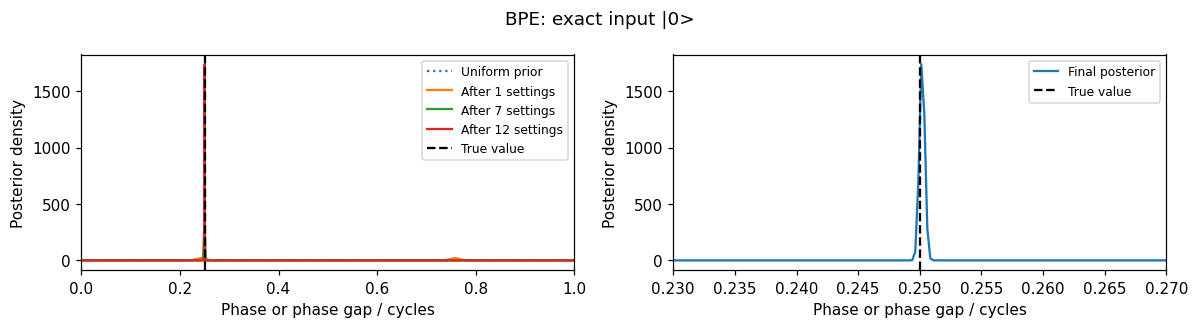

In [8]:
SHOTS = 256
SEED = 20261108
L_VALUES = [1,2,4,8,16,32]
settings=[(L,beta) for L in L_VALUES for beta in [0.,-np.pi/2]]

def plot_updates(grid,posteriors,truth,title):
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    density_scale=1/(grid[1]-grid[0])
    axes[0].plot(grid,np.ones_like(grid),ls=':',label='Uniform prior')
    for i in sorted(set([0,len(posteriors)//2,len(posteriors)-1])):
        axes[0].plot(grid,posteriors[i]*density_scale,label=f'After {i+1} settings')
    axes[1].plot(grid,posteriors[-1]*density_scale,label='Final posterior')
    for ax in axes:
        ax.axvline(truth,color='black',ls='--',label='True value')
        ax.set(xlabel='Phase or phase gap / cycles',ylabel='Posterior density');ax.legend(fontsize=8)
    axes[0].set_xlim(0,1);axes[1].set_xlim(max(0,truth-.02),min(1,truth+.02))
    fig.suptitle(title);plt.tight_layout();plt.show();plt.close(fig)

def print_data(data):
    print(' L  beta/pi  shots  observed n0  exact P0')
    for L,beta,R,n0,p0 in data:
        print(f'{L:2d} {beta/np.pi:8.2f} {R:6d} {n0:12d} {p0:9.4f}')

post_exact,data_exact=bayes_update(GRID,settings,lambda L,b:bpe_probability([1,0],L,b),shots=SHOTS,seed=SEED)
plot_updates(GRID,post_exact,PHASES[0],'BPE: exact input |0>')
print_data(data_exact)
print(posterior_summary(GRID,post_exact[-1]))
print('Total shots:',SHOTS*len(settings),'total controlled-U repetitions:',SHOTS*sum(L for L,_ in settings))

### 課題3：BPEの設定を変える

1. `SHOTS`を64、256、1024へ変え、同じ`SEED`で最終分布の幅を比較する。
2. `L_VALUES=[4]*6`へ変更する。二つのβを使っても区別できない候補は何個か。
3. 更新関数に渡す真の確率を`bpe_probability([0,1],L,b)`へ変え、位相3/4を推定する。

<details><summary>解答例</summary>
shotsは統計変動を減らします。L=4固定ではφとφ+k/4が同じ信号を与え、4候補が残ります。
励起状態へ変えた場合の正解はφ=3/4です。推定変数や尤度の式を変える必要はありません。
`L_VALUES`は後のBPDEでも使います。比較前に[1,2,4,8,16,32]へ戻してください。
</details>

## 4．BPDE・Fig. 1B型：二つの固有位相の差を読む

補助の二つの枝へ異なる固有状態を準備します。
$$|\Psi\rangle=(|0\rangle_a|0\rangle_s+|1\rangle_a|1\rangle_s)/\sqrt2.$$
準備を$W_B$とすると、回路は次の形です。箱は両線に作用します。

```text
a: |0> ──┌─────┐────────P(β)──┌──────┐──M_a
         │ W_B │              │ W_B† │
s: |0> ──└─────┘──[U^L]───────└──────┘─────
```

$U^L$は**系にだけ、補助で制御せず**作用させます。準備の制御操作は残ります。
時間発展後の二つの枝には$e^{2\pi iL\phi_0}$と$e^{i\beta}e^{2\pi iL\phi_1}$が付きます。
共通位相をくくると、相対位相は$2\pi L\Delta+\beta$です。
$$P_B(a=0)=\frac{1+\cos(2\pi L\Delta+\beta)}2,\qquad\Delta=1/2.$$

次セルは準備・逆準備を含む回路の確率を式と照合します。
`eta=0`が厳密準備です。`eta>0`は励起側に$|0\rangle$が混入した診断例で、
信号は$[1+\eta\cos\beta+(1-\eta)\cos(2\pi L\Delta+\beta)]/2$になります。

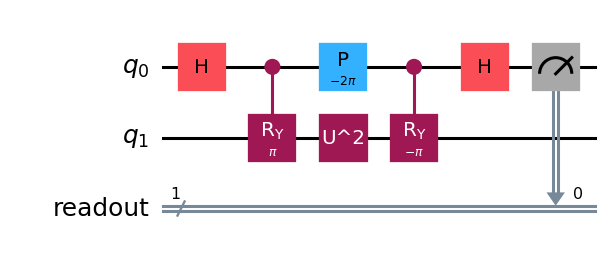

In [9]:
def preparation_b(eta=0.0):
    qc = QuantumCircuit(2, name="W_B")  # q0=a, q1=s
    qc.h(0)
    qc.cry(2*np.arccos(np.sqrt(eta)), 0, 1)
    return qc

def bpde_circuit(eta=0.0, L=1, beta=0.0):
    prep = preparation_b(eta)
    qc = QuantumCircuit(2)
    qc.compose(prep, inplace=True)
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}"), [1])
    qc.p(beta, 0)
    qc.compose(prep.inverse(), inplace=True)
    return qc

def bpde_probability(eta, L, beta):
    return 0.5*(1 + eta*np.cos(beta) + (1-eta)*np.cos(TAU*L*GAP+beta))

draw_measured(bpde_circuit(eta=0, L=2, beta=-TAU*2*GAP), [0])
for eta in [0, 0.25, 0.7]:
    for L in [1, 2, 5]:
        for beta in [0.0, 0.31, -1.7]:
            assert np.isclose(ancilla_zero(bpde_circuit(eta, L, beta)),
                              bpde_probability(eta, L, beta), atol=ATOL)

### 4.1．BPDEのベイズ更新例

第3節と同じ一様事前分布・測定設定・二項更新関数を使い、未知変数をφからΔへ置き換えます。
厳密準備では尤度の形が同じなので、`bayes_update`の再利用ができます。
次セルで途中と最終の事後、各設定のcountsを確認してください。

 L  beta/pi  shots  observed n0  exact P0
 1     0.00    256            0    0.0000
 1    -0.50    256          136    0.5000
 2     0.00    256          256    1.0000
 2    -0.50    256          131    0.5000
 4     0.00    256          256    1.0000
 4    -0.50    256          141    0.5000
 8     0.00    256          256    1.0000
 8    -0.50    256          132    0.5000
16     0.00    256          256    1.0000
16    -0.50    256          135    0.5000
32     0.00    256          256    1.0000
32    -0.50    256          145    0.5000
{'MAP': 0.5003662109375, 'mean': 0.5004486778523835, 'equal_tail_95': (0.4998933139301034, 0.50079601755697)}


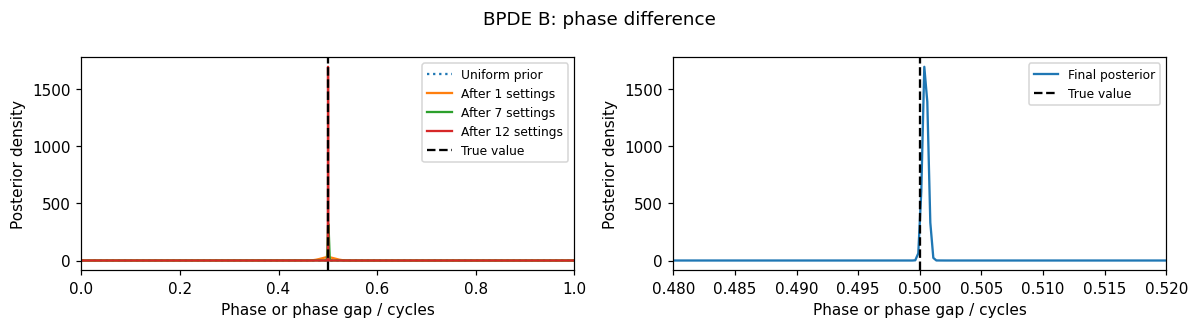

In [10]:
settings=[(L,beta) for L in L_VALUES for beta in [0.,-np.pi/2]]
post_gap,data_gap=bayes_update(GRID,settings,lambda L,b:bpde_probability(0,L,b),shots=SHOTS,seed=83)
plot_updates(GRID,post_gap,GAP,'BPDE B: phase difference')
print_data(data_gap)
print(posterior_summary(GRID,post_gap[-1]))

### 課題4：絶対位相と差を区別する

$K\to K+cI$とすると、$U^L$の両固有位相に$cL$が加わります。
式から、BPEの位相とBPDEの差がどう変わるか説明してください。
また、`eta=1`では二つの枝が同じ状態になります。何の差を測っているでしょうか。

<details><summary>解答例</summary>
BPEはφ+c（周期1）を読みます。BPDEでは共通位相が消え、差は変わりません。
eta=1では差0の信号です。近似状態を使っても本節の単一ギャップ尤度が常に正しいわけではありません。
</details>

## 5．Fig. 1C型：全0へ戻った回数で差を読む

一般の準備$W$で作った状態について、逆準備後の**全0**確率は
$$P_C(00)=|\langle\Psi|(P_a(\beta)\otimes U^L)|\Psi\rangle|^2.$$
枝の状態を$|\psi_0\rangle,|\psi_1\rangle$として
$$a_j=\langle\psi_j|U^L|\psi_j\rangle,\qquad
P_C(00)=\tfrac14|a_0+e^{i\beta}a_1|^2.$$
これは演習3〜5の全0測定と同じ式です。厳密固有状態ではFig. 1B型と同じ余弦になります。

```text
a: |0> ──┌─────┐────────P(β)──┌──────┐──M_a──┐
         │ W_C │              │ W_C† │       ├─ count(a=0 AND s=0)
s: |0> ──└─────┘──[U^L]───────└──────┘──M_s──┘
```

**同じ状態を準備しても、補助だけの測定は同じとは限りません。**
説明用に$W_C=W_B\,\mathrm{SWAP}$とします。初期00はSWAPで変わらず、準備状態は同じです。
逆準備の最後のSWAPで、Fig. 1B型で補助に出ていた情報が系へ移ります。
厳密準備eta=0のこの例では補助0の確率は常に1ですが、全0確率は位相差で変わります。
SWAPは原著の回路そのものではなく、Fig. 1C型の読出し原理を示す小さな実例です。

次セルはBとCの測定確率を掃引します。L=1、β=0では相対位相πなので、
数式の順$|a,s\rangle$でBは10、Cは01となることを確認してください。

B output probabilities in |a,s> order: {'00': 0.0, '01': 0.0, '10': 1.0, '11': 0.0}
C output probabilities in |a,s> order: {'00': 0.0, '01': 1.0, '10': 0.0, '11': 0.0}


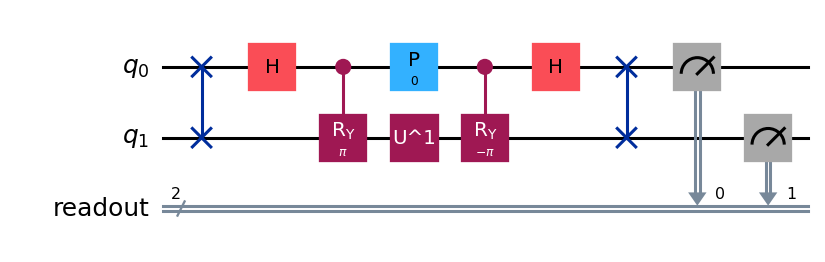

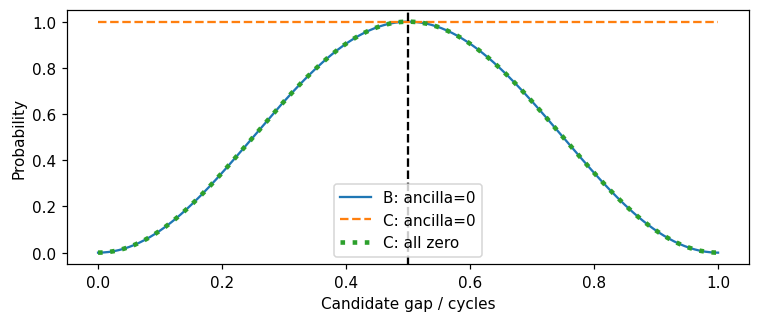

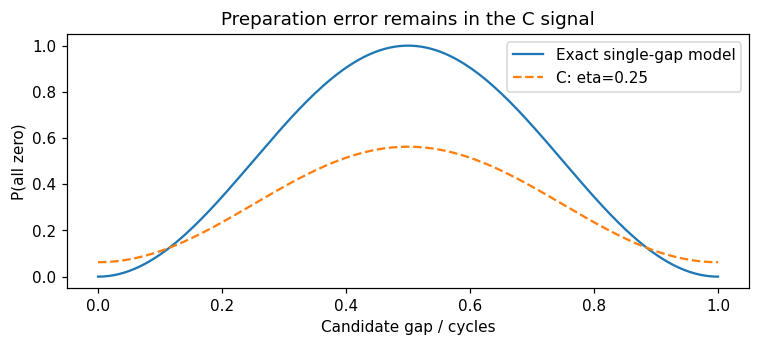

In [11]:
def preparation_c(eta=0.):
    qc=QuantumCircuit(2,name='W_C')
    qc.swap(0,1)
    qc.compose(preparation_b(eta),inplace=True)
    return qc

def return_circuit(eta=0.,L=1,beta=0.,kind='C'):
    prep=preparation_c(eta) if kind=='C' else preparation_b(eta)
    qc=QuantumCircuit(2)
    qc.compose(prep,inplace=True)
    qc.append(UnitaryGate(u_power(L),label=f'U^{L}'),[1])
    qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def measurement_probabilities(qc):
    sv=Statevector.from_instruction(qc)
    return float(sv.probabilities([0])[0]),float(abs(sv.data[0])**2)

def c_probability(eta,L,beta):
    ag=np.exp(1j*TAU*L*PHASES[0])
    ae=eta*ag+(1-eta)*np.exp(1j*TAU*L*PHASES[1])
    return .25*abs(ag+np.exp(1j*beta)*ae)**2

np.testing.assert_allclose(Statevector.from_instruction(preparation_b()).data,
    Statevector.from_instruction(preparation_c()).data,atol=ATOL)
draw_measured(return_circuit(),[0,1])
candidates=np.linspace(0,1,241)
curves={kind:np.array([measurement_probabilities(return_circuit(beta=-TAU*e,kind=kind)) for e in candidates]) for kind in ['B','C']}
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(candidates,curves['B'][:,0],label='B: ancilla=0')
ax.plot(candidates,curves['C'][:,0],'--',label='C: ancilla=0')
ax.plot(candidates,curves['C'][:,1],':',lw=3,label='C: all zero')
ax.axvline(GAP,color='black',ls='--');ax.set(xlabel='Candidate gap / cycles',ylabel='Probability');ax.legend()
plt.show();plt.close(fig)
np.testing.assert_allclose(curves['C'][:,0],1,atol=ATOL)
np.testing.assert_allclose(curves['C'][:,1],curves['B'][:,0],atol=ATOL)
for kind in ['B','C']:
    sv=Statevector.from_instruction(return_circuit(L=1,beta=0,kind=kind))
    print(kind,'output probabilities in |a,s> order:',{f'{a}{s}':round(float(abs(sv.data[2*s+a])**2),6) for a in [0,1] for s in [0,1]})
for eta in [0,.25,.7]:
    for L in [1,2,5]:
        for beta in [0,.31,-1.7]:
            for kind in ['B','C']:
                np.testing.assert_allclose(measurement_probabilities(return_circuit(eta,L,beta,kind))[1],c_probability(eta,L,beta),atol=ATOL)
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(candidates,single_phase_model(GAP,1,-TAU*candidates),label='Exact single-gap model')
ax.plot(candidates,c_probability(.25,1,-TAU*candidates),'--',label='C: eta=0.25')
ax.set(xlabel='Candidate gap / cycles',ylabel='P(all zero)',title='Preparation error remains in the C signal')
ax.legend();plt.show();plt.close(fig)

### 5.1．全0のcountsからベイズ更新する

1設定ごとに、全R shotsのうち**a=0かつs=0**だった$n_{00}$を数えます。
厳密準備なら$P_C(00|\Delta)$は第3節と同じ余弦なので、
$$p_{\rm new}(\Delta)\propto p_{\rm old}(\Delta)
 P_C(00|\Delta)^{n_{00}}[1-P_C(00|\Delta)]^{R-n_{00}}.$$
補助0だったショットだけを取り出して割る条件付き確率は使いません。
次セルでは**実際のC回路の全0確率**から二項模擬測定を生成し、同じ更新関数へ渡します。
二項サンプリングは2ビットの全4通りの測定結果から00だけを集計する場合と同じ周辺分布です。
BとCで同じ乱数seedを使い、同じ理想確率が同じ事後を与えることも確かめます。

 L  beta/pi  shots  observed n0  exact P0
 1     0.00    256            0    0.0000
 1    -0.50    256          136    0.5000
 2     0.00    256          256    1.0000
 2    -0.50    256          131    0.5000
 4     0.00    256          256    1.0000
 4    -0.50    256          141    0.5000
 8     0.00    256          256    1.0000
 8    -0.50    256          132    0.5000
16     0.00    256          256    1.0000
16    -0.50    256          135    0.5000
32     0.00    256          256    1.0000
32    -0.50    256          145    0.5000
{'MAP': 0.5003662109375, 'mean': 0.5004486778523835, 'equal_tail_95': (0.4998933139301034, 0.50079601755697)}
B/C: same ideal signal and same-seed posterior checked


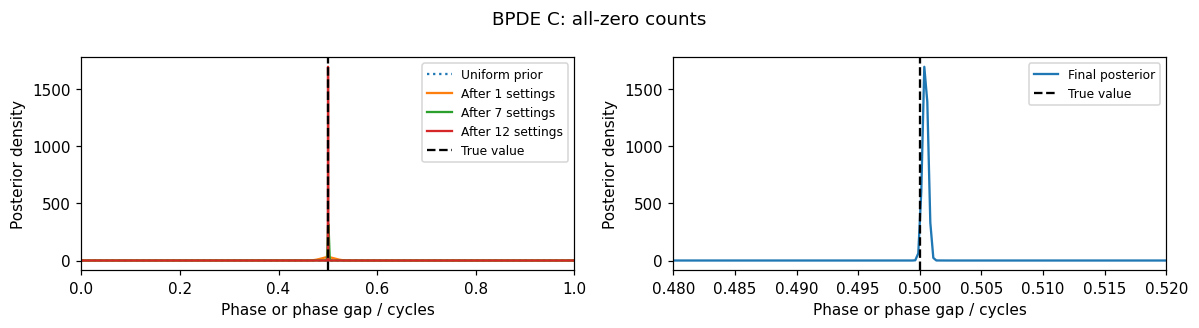

In [12]:
post_c,data_c=bayes_update(GRID,settings,
    lambda L,b:measurement_probabilities(return_circuit(eta=0,L=L,beta=b,kind='C'))[1],
    shots=SHOTS,seed=83)
plot_updates(GRID,post_c,GAP,'BPDE C: all-zero counts')
print_data(data_c)  # この表のn0列は全0の回数n00
print(posterior_summary(GRID,post_c[-1]))
np.testing.assert_allclose(post_c,post_gap,atol=ATOL)
print('B/C: same ideal signal and same-seed posterior checked')

### 課題5：全0測定の意味

1. β=0、L=1で、BとCの補助だけ／全0確率を説明する。
2. Cのベイズ例で生成確率を`measurement_probabilities(...)[0]`へ変えると、正しい差を推定できるか。
   必ず元の`[1]`に戻す。
3. `SHOTS`を変え、全0countsと事後分布を比較する。
4. `eta=.25`の全0確率と単一ギャップ余弦を比べる。状態準備の誤りを全0測定だけで除けるか。

<details><summary>解答例</summary>
1. β=0、L=1ではBの補助0も全0も0、Cの補助0は1、全0は0です。Cの補助だけから差は読めません。
2. Cの補助だけなら全設定でn₀=Rです。差に依存しないデータへ差依存の尤度を当てはめるため、
   得られた事後を正しいギャップの推定と解釈できません。
3. 全0の頻度の標準偏差は√[P(1−P)/R]で、shots増加によりばらつきが減ります。
   正しい尤度なら事後も一般に狭くなりますが、周期の別候補は測定計画にも依存します。
4. eta>0ではa₁が複数の固有位相を含み、示した2本の曲線は一致しません。
   全0は近似準備状態への戻りを数え、厳密固有状態へ浄化する操作ではありません。
</details>

## 6．次の分子計算へ

演習2では$U=e^{-iH\Delta t}$を使い、$\phi=-E\Delta t/(2\pi)\pmod1$です。
本冊のβ=−2πLεに、位相候補ε=−E_trialΔt/(2π)を代入するとβ=E_trial tになります。
ギャップ候補でも同様にβ=ΔE_trial tです。これが演習3〜5の符号規約です。

| 本冊の測定 | 推定する変数 | 次冊以降への接続 |
|---|---|---|
| QPE | φを表すy/2^m | 有限ビット分解能と化学のエネルギー換算 |
| BPE | 単一位相φ | 事前×二項尤度→事後 |
| BPDE B | 二状態の位相差Δ | 制御なしの系時間発展 |
| BPDE C | 同じΔ、全0countsで更新 | 準備・逆準備を含むH₂/JW・H₄回路 |

演習5は、全0確率の曲線をGaussianフィットして更新する著者コードの近似手順です。
本冊の二項尤度によるグリッド更新と同じ計算法ではありません。

[参考論文](https://doi.org/10.1073/pnas.2425026122)：Fig. 1B/1Cの読出しを参照。
本冊は2×2行列を用いた説明用実装です。